## 0. Configuración del entorno
Se importan las librerías y se fija una **semilla** para que los resultados sean reproducibles.

In [1]:
import os, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)
from IPython.display import display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

os.makedirs("figuras", exist_ok=True)   # aquí se guardan las gráficas para el informe
os.makedirs("resultados", exist_ok=True)
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## 1. Distribución y preprocesamiento de datos
- **Train:** el modelo aprende (ajusta pesos) con estos datos.
- **Dev (validación):** sirve para comparar hiperparámetros y detectar overfitting. No se usa para entrenar.
- **Test:** se usa **una sola vez al final** para estimar el desempeño real. Si se usara para decidir hiperparámetros, la estimación sería optimista.

Preprocesamiento: normalización de píxeles de [0, 255] a [0, 1], aplanado de 28x28 a 784 características y división **estratificada** (mantiene la proporción de cada clase).

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


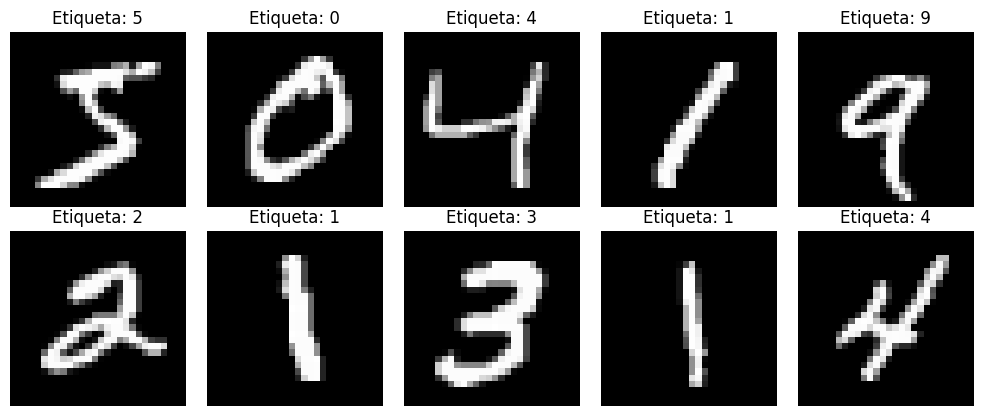

Train: (54000, 784) | Dev: (6000, 784) | Test: (10000, 784)


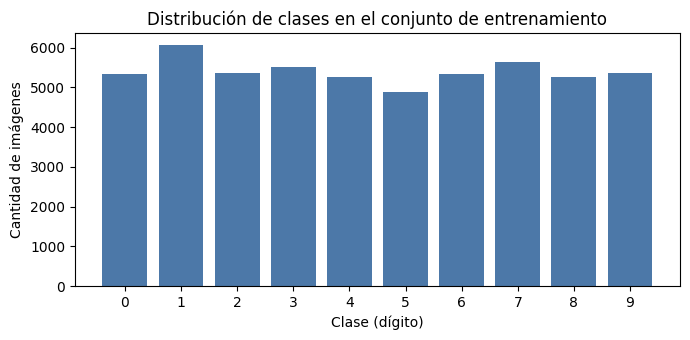

In [2]:
# Carga de MNIST: 60.000 imágenes de entrenamiento y 10.000 de prueba (dígitos 0-9)
(x_full, y_full), (x_test, y_test) = keras.datasets.mnist.load_data()

# Normalización a [0, 1]
x_full = x_full.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Muestras de ejemplo
fig, axes = plt.subplots(2, 5, figsize=(10, 4.2))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(x_full[i], cmap="gray")
    ax.set_title(f"Etiqueta: {y_full[i]}")
    ax.axis("off")
plt.tight_layout()
plt.savefig("figuras/01_muestras_mnist.png", dpi=130)
plt.show()

# Aplanado 28x28 -> 784
x_full = x_full.reshape(-1, 784)
x_test = x_test.reshape(-1, 784)

# División train / dev (10 % para dev), estratificada por clase
x_train, x_dev, y_train, y_dev = train_test_split(
    x_full, y_full, test_size=0.10, random_state=SEED, stratify=y_full)

n_train, n_dev, n_test = len(x_train), len(x_dev), len(x_test)
print(f"Train: {x_train.shape} | Dev: {x_dev.shape} | Test: {x_test.shape}")

# Distribución de clases en train
plt.figure(figsize=(7, 3.5))
plt.bar(range(10), np.bincount(y_train), color="#4C78A8")
plt.xticks(range(10))
plt.xlabel("Clase (dígito)")
plt.ylabel("Cantidad de imágenes")
plt.title("Distribución de clases en el conjunto de entrenamiento")
plt.tight_layout()
plt.savefig("figuras/02_distribucion_clases.png", dpi=130)
plt.show()

## 2. Funciones auxiliares
- `build_model`: construye un perceptrón multicapa (MLP) con capas densas ReLU y salida softmax de 10 clases. Recibe los **hiperparámetros** (optimizador, neuronas por capa, dropout, L1, L2).
- `train`: entrena usando el conjunto dev como validación.
- `plot_curves`: grafica curvas por época.

In [ ]:
def build_model(optimizer, units=(256, 128), dropout=0.0, l1=0.0, l2=0.0):
    # Regularizador de pesos (L1, L2 o ambos) aplicado a las capas ocultas
    reg = regularizers.l1_l2(l1=l1, l2=l2) if (l1 > 0 or l2 > 0) else None

    model = keras.Sequential([layers.Input(shape=(784,))])
    for u in units:
        model.add(layers.Dense(u, activation="relu", kernel_regularizer=reg))
        if dropout > 0:
            model.add(layers.Dropout(dropout))   # apaga neuronas al azar solo en entrenamiento
    model.add(layers.Dense(10, activation="softmax"))

    model.compile(optimizer=optimizer,
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    return model


def train(model, epochs=10, batch_size=128, callbacks=None):
    return model.fit(x_train, y_train,
                     validation_data=(x_dev, y_dev),
                     epochs=epochs, batch_size=batch_size,
                     callbacks=callbacks, verbose=0)


def plot_curves(histories, metric, title, ylabel, filename):
    plt.figure(figsize=(8, 4.5))
    for name, h in histories.items():
        plt.plot(range(1, len(h.history[metric]) + 1), h.history[metric], label=name)
    plt.title(title)
    plt.xlabel("Época")
    plt.ylabel(ylabel)
    plt.grid(alpha=0.3)
    plt.legend(fontsize=8)
    plt.tight_layout()
    plt.savefig(filename, dpi=130)
    plt.show()

## 3. Técnicas de optimización
Se entrena la **misma arquitectura** (784-256-128-10) cambiando solo el optimizador y el learning rate, para aislar su efecto:

- **SGD:** actualiza los pesos con el gradiente de cada mini-batch.
- **SGD + Momentum:** acumula una "velocidad" de gradientes pasados, lo que suaviza y acelera la convergencia.
- **RMSprop:** adapta el learning rate por parámetro según la magnitud reciente de sus gradientes.
- **Adam:** combina momentum y adaptación del learning rate.

El **learning rate** es el hiperparámetro más sensible: muy alto produce inestabilidad, muy bajo hace el aprendizaje lento.

SGD (lr=0.01)                       acc dev = 0.9320
SGD + Momentum (lr=0.01, m=0.9)     acc dev = 0.9732
RMSprop (lr=0.001)                  acc dev = 0.9787
Adam (lr=0.01)                      acc dev = 0.9642
Adam (lr=0.001)                     acc dev = 0.9770
Adam (lr=0.0001)                    acc dev = 0.9660


,Optimizador,Acc train,Acc dev,Loss dev
0,SGD (lr=0.01),0.9334,0.9320,0.2461
1,"SGD + Momentum (lr=0.01, m=0.9)",0.9861,0.9732,0.0951
2,RMSprop (lr=0.001),0.9974,0.9787,0.1099
3,Adam (lr=0.01),0.9830,0.9642,0.2287
4,Adam (lr=0.001),0.9965,0.9770,0.1076
5,Adam (lr=0.0001),0.9730,0.9660,0.1298


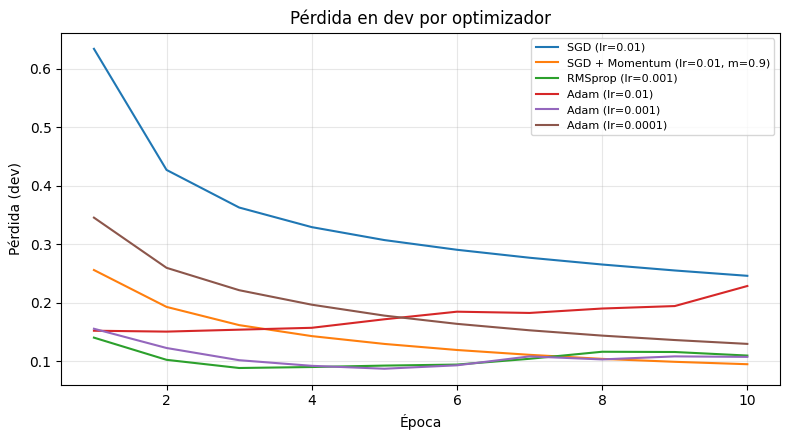

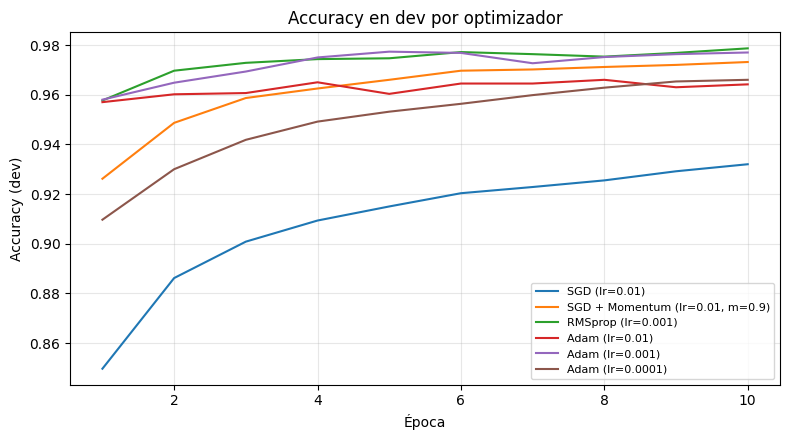

In [4]:
EPOCHS = 10

opt_configs = {
    "SGD (lr=0.01)":                 lambda: keras.optimizers.SGD(learning_rate=0.01),
    "SGD + Momentum (lr=0.01, m=0.9)": lambda: keras.optimizers.SGD(learning_rate=0.01, momentum=0.9),
    "RMSprop (lr=0.001)":            lambda: keras.optimizers.RMSprop(learning_rate=0.001),
    "Adam (lr=0.01)":                lambda: keras.optimizers.Adam(learning_rate=0.01),
    "Adam (lr=0.001)":               lambda: keras.optimizers.Adam(learning_rate=0.001),
    "Adam (lr=0.0001)":              lambda: keras.optimizers.Adam(learning_rate=0.0001),
}

opt_histories, opt_rows = {}, []
for name, make_opt in opt_configs.items():
    keras.utils.set_random_seed(SEED)           # misma inicialización para comparar justo
    model = build_model(make_opt())
    h = train(model, EPOCHS)
    opt_histories[name] = h
    opt_rows.append({
        "Optimizador": name,
        "Acc train": h.history["accuracy"][-1],
        "Acc dev": h.history["val_accuracy"][-1],
        "Loss dev": h.history["val_loss"][-1],
    })
    print(f"{name:35s} acc dev = {h.history['val_accuracy'][-1]:.4f}")

opt_df = pd.DataFrame(opt_rows).round(4)
opt_df.to_csv("resultados/optimizacion.csv", index=False)
display(opt_df)

plot_curves(opt_histories, "val_loss", "Pérdida en dev por optimizador", "Pérdida (dev)",
            "figuras/03_opt_val_loss.png")
plot_curves(opt_histories, "val_accuracy", "Accuracy en dev por optimizador", "Accuracy (dev)",
            "figuras/04_opt_val_accuracy.png")

## 4. Regularización, bias y variance
Se usa una red **más grande** (784-512-512-256-10) y más épocas (30) con Adam (lr=0.001), para que el overfitting sea observable. Luego se aplican:

- **L1:** penaliza la suma de |pesos| (tiende a pesos exactamente cero).
- **L2:** penaliza la suma de pesos al cuadrado (pesos pequeños, "weight decay").
- **Dropout:** apaga una fracción de neuronas en cada paso de entrenamiento.
- **Early Stopping:** detiene el entrenamiento cuando la pérdida en dev deja de mejorar y restaura los mejores pesos.

**Bias y variance:** el *error en train* aproxima el **sesgo** (underfitting si es alto); la *brecha* error dev - error train aproxima la **varianza** (overfitting si es grande). El **tradeoff** consiste en reducir la varianza sin aumentar demasiado el sesgo.

Sin regularización               acc train = 0.9958 | acc dev = 0.9767
L2 (1e-4)                        acc train = 0.9912 | acc dev = 0.9727
L1 (1e-5)                        acc train = 0.9918 | acc dev = 0.9733
Dropout (0.3)                    acc train = 0.9957 | acc dev = 0.9802
Early Stopping                   acc train = 0.9860 | acc dev = 0.9700
L2 + Dropout + Early Stopping    acc train = 0.9925 | acc dev = 0.9787


,Configuración,Épocas,Acc train,Acc dev,Error train (sesgo),Error dev,Brecha (varianza)
0,Sin regularización,12,0.9958,0.9767,0.0042,0.0233,0.0191
1,L2 (1e-4),12,0.9912,0.9727,0.0088,0.0273,0.0185
2,L1 (1e-5),12,0.9918,0.9733,0.0082,0.0267,0.0185
3,Dropout (0.3),12,0.9957,0.9802,0.0043,0.0198,0.0156
4,Early Stopping,6,0.9860,0.9700,0.0140,0.0300,0.0160
5,L2 + Dropout + Early Stopping,12,0.9925,0.9787,0.0075,0.0213,0.0138


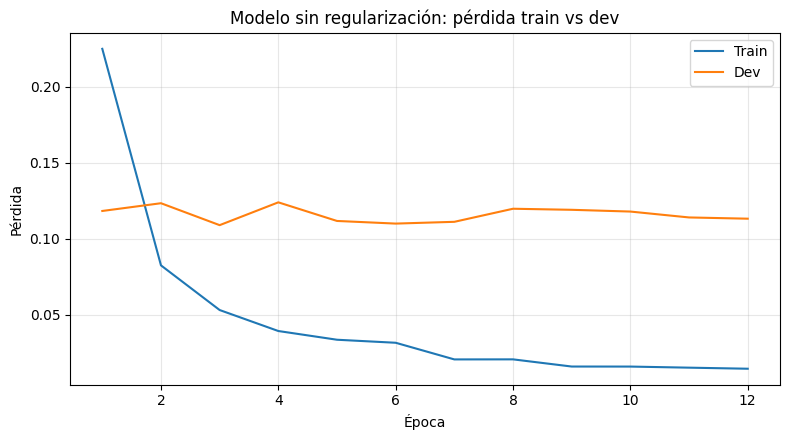

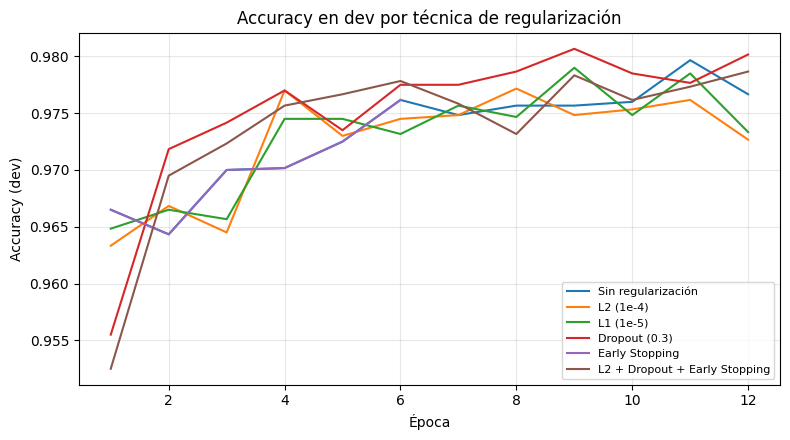

In [7]:
EPOCHS_REG = 12
BIG = (512, 512, 256)

def make_adam():
    return keras.optimizers.Adam(learning_rate=0.001)

def make_early():
    return keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)

reg_configs = {
    "Sin regularización":            dict(kw={},                          early=False),
    "L2 (1e-4)":                     dict(kw=dict(l2=1e-4),               early=False),
    "L1 (1e-5)":                     dict(kw=dict(l1=1e-5),               early=False),
    "Dropout (0.3)":                 dict(kw=dict(dropout=0.3),           early=False),
    "Early Stopping":                dict(kw={},                          early=True),
    "L2 + Dropout + Early Stopping": dict(kw=dict(l2=1e-4, dropout=0.3),  early=True),
}

reg_histories, reg_models, reg_rows = {}, {}, []
for name, cfg in reg_configs.items():
    keras.utils.set_random_seed(SEED)
    model = build_model(make_adam(), units=BIG, **cfg["kw"])
    cbs = [make_early()] if cfg["early"] else None
    h = train(model, EPOCHS_REG, callbacks=cbs)

    # Evaluación final con los pesos finales (con Early Stopping, los mejores restaurados)
    _, acc_tr = model.evaluate(x_train, y_train, verbose=0)
    _, acc_dv = model.evaluate(x_dev, y_dev, verbose=0)

    reg_histories[name] = h
    reg_models[name] = model
    reg_rows.append({
        "Configuración": name,
        "Épocas": len(h.history["loss"]),
        "Acc train": acc_tr,
        "Acc dev": acc_dv,
        "Error train (sesgo)": 1 - acc_tr,
        "Error dev": 1 - acc_dv,
        "Brecha (varianza)": acc_tr - acc_dv,
    })
    print(f"{name:32s} acc train = {acc_tr:.4f} | acc dev = {acc_dv:.4f}")

reg_df = pd.DataFrame(reg_rows).round(4)
reg_df.to_csv("resultados/regularizacion.csv", index=False)
display(reg_df)

# Evidencia de overfitting: pérdida train vs dev del modelo sin regularización
h0 = reg_histories["Sin regularización"]
plt.figure(figsize=(8, 4.5))
plt.plot(range(1, len(h0.history["loss"]) + 1), h0.history["loss"], label="Train")
plt.plot(range(1, len(h0.history["val_loss"]) + 1), h0.history["val_loss"], label="Dev")
plt.title("Modelo sin regularización: pérdida train vs dev")
plt.xlabel("Época"); plt.ylabel("Pérdida"); plt.grid(alpha=0.3); plt.legend()
plt.tight_layout()
plt.savefig("figuras/05_overfitting_baseline.png", dpi=130)
plt.show()

plot_curves(reg_histories, "val_accuracy", "Accuracy en dev por técnica de regularización",
            "Accuracy (dev)", "figuras/06_reg_val_accuracy.png")

## 5. Evaluación final con métricas de clasificación
Se elige la configuración con **mejor accuracy en dev** y se evalúa **una sola vez** en test.

- **Accuracy:** proporción de aciertos totales.
- **Precision:** de lo que el modelo predijo como clase *c*, qué fracción era realmente *c*.
- **Recall:** de lo que realmente era clase *c*, qué fracción detectó el modelo.
- **F1:** media armónica entre precision y recall.
- **Matriz de confusión:** filas = clase real, columnas = clase predicha.

Para las métricas globales se usa promedio **macro** (cada clase pesa igual).

Modelo seleccionado (mejor en dev): Dropout (0.3)
Accuracy            : 0.9825
Precision (macro)   : 0.9824
Recall (macro)      : 0.9824
F1 (macro)          : 0.9824

              precision    recall  f1-score   support

           0     0.9838    0.9898    0.9868       980
           1     0.9895    0.9947    0.9921      1135
           2     0.9931    0.9719    0.9824      1032
           3     0.9764    0.9822    0.9793      1010
           4     0.9887    0.9776    0.9831       982
           5     0.9810    0.9843    0.9827       892
           6     0.9773    0.9875    0.9823       958
           7     0.9796    0.9805    0.9801      1028
           8     0.9775    0.9805    0.9790       974
           9     0.9772    0.9752    0.9762      1009

    accuracy                         0.9825     10000
   macro avg     0.9824    0.9824    0.9824     10000
weighted avg     0.9825    0.9825    0.9825     10000



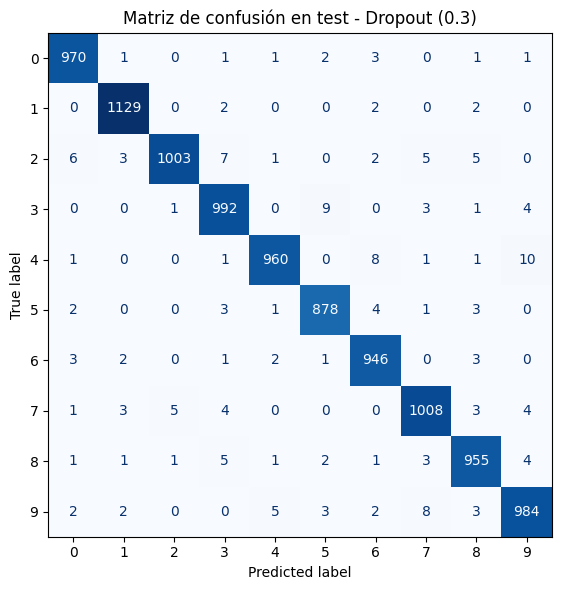

Real 4 predicho como 9: 10 veces
Real 3 predicho como 5: 9 veces
Real 9 predicho como 7: 8 veces


In [8]:
best_name = reg_df.sort_values("Acc dev").iloc[-1]["Configuración"]
best_model = reg_models[best_name]
print("Modelo seleccionado (mejor en dev):", best_name)

y_prob = best_model.predict(x_test, verbose=0)
y_pred = y_prob.argmax(axis=1)

final_metrics = {
    "Accuracy":  accuracy_score(y_test, y_pred),
    "Precision (macro)": precision_score(y_test, y_pred, average="macro"),
    "Recall (macro)":    recall_score(y_test, y_pred, average="macro"),
    "F1 (macro)":        f1_score(y_test, y_pred, average="macro"),
}
for k, v in final_metrics.items():
    print(f"{k:20s}: {v:.4f}")

print()
print(classification_report(y_test, y_pred, digits=4))
report_dict = classification_report(y_test, y_pred, digits=4, output_dict=True)

# Matriz de confusión
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(cm, display_labels=list(range(10))).plot(
    ax=ax, cmap="Blues", values_format="d", colorbar=False)
ax.set_title(f"Matriz de confusión en test - {best_name}")
plt.tight_layout()
plt.savefig("figuras/07_matriz_confusion.png", dpi=130)
plt.show()

# Confusiones más frecuentes (fuera de la diagonal)
cm_off = cm.copy()
np.fill_diagonal(cm_off, 0)
idx = np.argsort(cm_off.ravel())[::-1][:3]
confusions = [(int(i // 10), int(i % 10), int(cm_off.ravel()[i])) for i in idx]
for real, pred, n in confusions:
    print(f"Real {real} predicho como {pred}: {n} veces")

pd.DataFrame([final_metrics]).round(4).to_csv("resultados/metricas_test.csv", index=False)